# Age at which young people leave the parental home in the EU (2016–2024)
Main variable: `leave_age_total` – average age at which young people leave the parental home (Eurostat-style indicator), 27 EU countries × 9 years.
Note: "EU mean/median" below always means the **unweighted** mean/median across countries (not population-weighted).

## 0. Setup

In [ ]:
suppressPackageStartupMessages({
  library(dplyr); library(tidyr); library(ggplot2); library(forcats)
  library(ggrepel); library(broom); library(knitr)
})
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
theme_set(theme_minimal(base_size = 12) +
          theme(plot.title = element_text(face = "bold"), legend.position = "bottom"))
dir.create("../figures", showWarnings = FALSE)                      # PNGs go here
save_fig <- function(p, name, w = 10, h = 6) ggsave(file.path("../figures/main_analysis", name), p, width = w, height = h, dpi = 150, bg = "white")
tab <- function(x, d = 2) IRdisplay::display_markdown(paste(knitr::kable(x, digits = d, format = "pipe"), collapse = "\n"))

# Data
d <- read.csv("../../../data/leaving_home_clean_data.csv", stringsAsFactors = FALSE)
d$region <- factor(d$region, levels = c("Nordic", "Western", "Southern", "Eastern"))
reg_cols <- c(Nordic = "#0072B2", Western = "#E69F00", Southern = "#D55E00", Eastern = "#009E73")

# Descriptive-stat helper: mean, median, variance, SD, min, max, 25/75/90th percentiles by group
desc <- function(df, x, ...) {
  df %>% group_by(...) %>% summarise(
    n = n(), mean = mean({{x}}), median = median({{x}}), variance = var({{x}}), sd = sd({{x}}),
    min = min({{x}}), max = max({{x}}),
    p25 = quantile({{x}}, .25, names = FALSE), p75 = quantile({{x}}, .75, names = FALSE),
    p90 = quantile({{x}}, .90, names = FALSE), .groups = "drop")
}

## 1. Data overview

In [2]:
cat("Dimensions (rows x cols):", dim(d), "\n")
cat("Countries:", n_distinct(d$country), "| Years:", min(d$year), "-", max(d$year), "\n")
cat("Missing values:", sum(is.na(d)), "| Balanced panel (9 obs per country):", all(table(d$country) == 9), "\n")
cat("Countries per region:\n"); print(table(distinct(d, country, region)$region))

# Summary statistics of all numeric variables
d %>% select(leave_age_total, leave_age_men, leave_age_women, gender_gap, price_income_ratio,
             owners_pct, gdp_per_capita_eur, employment_rate_20_64) %>%
  pivot_longer(everything(), names_to = "variable") %>%
  group_by(variable) %>%
  summarise(mean = mean(value), sd = sd(value), min = min(value), q25 = quantile(value, .25),
            median = median(value), q75 = quantile(value, .75), max = max(value)) %>% tab()

Dimensions (rows x cols): 243 12 


Countries: 27 | Years: 2016 - 2024 


Missing values: 0 | Balanced panel (9 obs per country): TRUE 


Countries per region:



  Nordic  Western Southern  Eastern 
       3        7        6       11 


|variable              |     mean|       sd|     min|      q25|   median|      q75|       max|
|:---------------------|--------:|--------:|-------:|--------:|--------:|--------:|---------:|
|employment_rate_20_64 |    74.32|     5.68|   55.90|    71.25|    75.40|    78.35|     83.50|
|gdp_per_capita_eur    | 33935.27| 22528.93| 7070.00| 17840.00| 27220.00| 43520.00| 128710.00|
|gender_gap            |     1.95|     1.00|   -1.20|     1.40|     1.80|     2.40|      4.90|
|leave_age_men         |    27.62|     3.42|   17.50|    24.75|    27.80|    30.30|     34.80|
|leave_age_total       |    26.66|     3.13|   17.50|    24.00|    26.90|    29.10|     33.40|
|leave_age_women       |    25.67|     2.88|   17.60|    23.20|    25.80|    28.00|     32.50|
|owners_pct            |    75.39|    11.23|   46.50|    69.45|    74.70|    83.50|     96.80|
|price_income_ratio    |    98.63|    13.81|   48.23|    90.97|    97.32|   105.58|    152.06|

### Outlier detection
Two rules: (a) **within-country**: an observation is flagged if it is ≥ 2 years away from that country's own median (captures sudden jumps), (b) **pooled Tukey fences** (1.5·IQR) on all country-years.

In [3]:
d <- d %>% group_by(country) %>%
  mutate(dev_from_country_median = leave_age_total - median(leave_age_total),
         outlier = abs(dev_from_country_median) >= 2) %>% ungroup()

q <- quantile(d$leave_age_total, c(.25, .75)); fence <- q + c(-1.5, 1.5) * diff(q)
cat("Pooled Tukey fences:", round(fence, 2), "\n")
cat("Pooled Tukey outliers:\n"); d %>% filter(leave_age_total < fence[1] | leave_age_total > fence[2]) %>%
  select(country, year, leave_age_total) %>% tab()

cat("Within-country outliers (>= 2 years from own median):\n")
d %>% filter(outlier) %>% select(country, year, leave_age_total, dev_from_country_median) %>% tab()

Pooled Tukey fences: 16.35 36.75 


Pooled Tukey outliers:


|country | year| leave_age_total|
|:-------|----:|---------------:|

Within-country outliers (>= 2 years from own median):


|country  | year| leave_age_total| dev_from_country_median|
|:--------|----:|---------------:|-----------------------:|
|Belgium  | 2017|            23.4|                    -2.1|
|Portugal | 2021|            33.3|                     4.3|
|Sweden   | 2018|            18.4|                    -2.6|
|Sweden   | 2019|            17.8|                    -3.2|
|Sweden   | 2020|            17.5|                    -3.5|

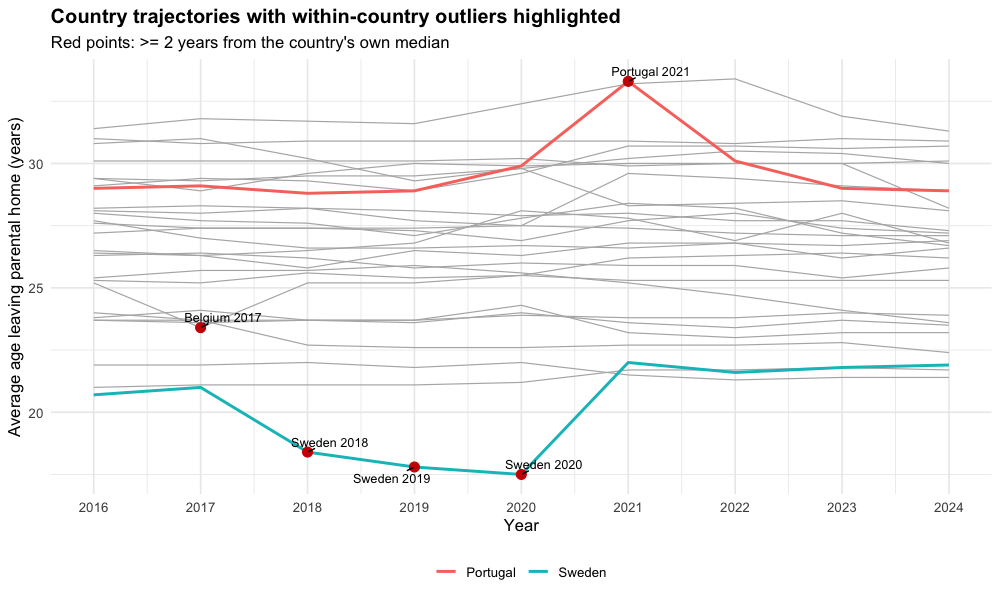

In [4]:
p <- ggplot(d, aes(year, leave_age_total, group = country)) +
  geom_line(colour = "grey70", linewidth = .4) +
  geom_line(data = filter(d, country %in% c("Sweden", "Portugal")), aes(colour = country), linewidth = 1) +
  geom_point(data = filter(d, outlier), colour = "red3", size = 3) +
  geom_text_repel(data = filter(d, outlier), aes(label = paste(country, year)), size = 3.2, min.segment.length = 0) +
  scale_x_continuous(breaks = 2016:2024) +
  labs(title = "Country trajectories with within-country outliers highlighted",
       subtitle = "Red points: >= 2 years from the country's own median", x = "Year",
       y = "Average age leaving parental home (years)", colour = NULL)
save_fig(p, "01_outliers.png"); p

**Findings**

- The data are a balanced panel: 243 rows = 27 countries × 9 years (2016–2024), no missing values. `leave_age_total` has mean 26.66, SD 3.13, range 17.5–33.4.
- No value falls outside the pooled Tukey fences (16.35–36.75), so there are no extreme outliers overall.
- Five observations are ≥ 2 years from their own country's median: **Sweden 2018–2020** (18.4, 17.8, 17.5; −2.6 to −3.5 years), **Portugal 2021** (33.3; +4.3) and Belgium 2017 (23.4; −2.1).
- Sweden returns to 22.0 in 2021 and Portugal to 30.1 in 2022, so these look like temporary breaks (possibly measurement-related – worth checking at the source) rather than a lasting shift.

## 2. Countries and regions

### 2.1 Descriptive statistics per country (2016–2024)

In [5]:
country_tab <- desc(d, leave_age_total, region, country) %>% arrange(desc(mean))
tab(country_tab)

|region   |country     |  n|  mean| median| variance|   sd|  min|  max|  p25|  p75|   p90|
|:--------|:-----------|--:|-----:|------:|--------:|----:|----:|----:|----:|----:|-----:|
|Eastern  |Croatia     |  9| 32.08|   31.8|     0.58| 0.76| 31.3| 33.4| 31.6| 32.4| 33.24|
|Eastern  |Slovakia    |  9| 30.90|   30.9|     0.00| 0.07| 30.8| 31.0| 30.9| 30.9| 31.00|
|Southern |Italy       |  9| 30.07|   30.1|     0.01| 0.09| 29.9| 30.2| 30.0| 30.1| 30.12|
|Southern |Greece      |  9| 29.89|   29.6|     0.59| 0.77| 28.9| 30.7| 29.3| 30.7| 30.70|
|Southern |Spain       |  9| 29.84|   29.8|     0.20| 0.45| 29.3| 30.5| 29.5| 30.2| 30.42|
|Southern |Portugal    |  9| 29.67|   29.0|     2.07| 1.44| 28.8| 33.3| 28.9| 29.9| 30.74|
|Eastern  |Bulgaria    |  9| 29.56|   29.9|     0.40| 0.63| 28.2| 30.0| 29.4| 30.0| 30.00|
|Southern |Malta       |  9| 29.38|   29.3|     1.25| 1.12| 28.1| 31.0| 28.4| 30.2| 30.84|
|Eastern  |Slovenia    |  9| 28.54|   28.3|     0.55| 0.74| 27.5| 29.6| 28.2| 29.1| 29.44|
|Eastern  |Romania     |  9| 27.89|   28.0|     0.08| 0.28| 27.3| 28.2| 27.7| 28.1| 28.12|
|Eastern  |Poland      |  9| 27.63|   27.7|     0.30| 0.55| 26.7| 28.4| 27.2| 28.0| 28.24|
|Southern |Cyprus      |  9| 27.39|   27.4|     0.10| 0.31| 26.9| 28.0| 27.2| 27.4| 27.76|
|Eastern  |Hungary     |  9| 27.34|   27.4|     0.03| 0.17| 27.1| 27.6| 27.2| 27.4| 27.52|
|Western  |Ireland     |  9| 27.08|   26.8|     0.48| 0.70| 26.3| 28.1| 26.5| 27.8| 28.02|
|Eastern  |Latvia      |  9| 26.76|   26.6|     0.17| 0.41| 26.2| 27.7| 26.6| 26.8| 27.14|
|Western  |Luxembourg  |  9| 26.50|   26.5|     0.12| 0.35| 25.8| 26.9| 26.3| 26.8| 26.82|
|Eastern  |Czechia     |  9| 25.97|   25.9|     0.09| 0.30| 25.4| 26.4| 25.8| 26.2| 26.32|
|Western  |Belgium     |  9| 25.51|   25.5|     0.89| 0.94| 23.4| 26.4| 25.2| 26.2| 26.32|
|Western  |Austria     |  9| 25.36|   25.3|     0.02| 0.12| 25.2| 25.6| 25.3| 25.4| 25.52|
|Eastern  |Lithuania   |  9| 25.10|   25.4|     0.64| 0.80| 23.6| 25.9| 24.7| 25.7| 25.74|
|Western  |Germany     |  9| 23.80|   23.8|     0.01| 0.11| 23.7| 24.0| 23.7| 23.9| 23.92|
|Western  |France      |  9| 23.71|   23.7|     0.05| 0.23| 23.4| 24.1| 23.6| 23.8| 24.02|
|Western  |Netherlands |  9| 23.51|   23.6|     0.16| 0.40| 23.0| 24.3| 23.2| 23.7| 23.82|
|Eastern  |Estonia     |  9| 22.91|   22.7|     0.30| 0.55| 22.4| 24.0| 22.6| 22.8| 23.76|
|Nordic   |Finland     |  9| 21.69|   21.8|     0.08| 0.28| 21.3| 22.0| 21.4| 21.9| 22.00|
|Nordic   |Denmark     |  9| 21.38|   21.2|     0.11| 0.33| 21.0| 21.8| 21.1| 21.7| 21.72|
|Nordic   |Sweden      |  9| 20.30|   21.0|     3.47| 1.86| 17.5| 22.0| 18.4| 21.8| 21.92|

### 2.2 Per region and per region2 (North/West vs South/East)
Region statistics pool all country-years of the region, so the variance includes between-country differences.

In [6]:
cat("Per region:\n"); tab(desc(d, leave_age_total, region))
cat("Per region2:\n"); tab(desc(d, leave_age_total, region_2groups))

Per region:


|region   |  n|  mean| median| variance|   sd|  min|  max|   p25|  p75|   p90|
|:--------|--:|-----:|------:|--------:|----:|----:|----:|-----:|----:|-----:|
|Nordic   | 27| 21.12|   21.5|     1.49| 1.22| 17.5| 22.0| 21.10| 21.8| 21.94|
|Western  | 63| 25.07|   25.2|     2.00| 1.41| 23.0| 28.1| 23.70| 26.3| 26.80|
|Southern | 54| 29.37|   29.5|     1.49| 1.22| 26.9| 33.3| 28.83| 30.1| 30.67|
|Eastern  | 99| 27.70|   27.6|     6.44| 2.54| 22.4| 33.4| 26.20| 29.5| 31.00|

Per region2:


|region_2groups |   n|  mean| median| variance|   sd|  min|  max|  p25|   p75|   p90|
|:--------------|---:|-----:|------:|--------:|----:|----:|----:|----:|-----:|-----:|
|North/West     |  90| 23.88|   23.7|     5.13| 2.27| 17.5| 28.1| 21.9| 25.58| 26.71|
|South/East     | 153| 28.29|   28.2|     5.31| 2.31| 22.4| 33.4| 27.1| 30.00| 30.90|

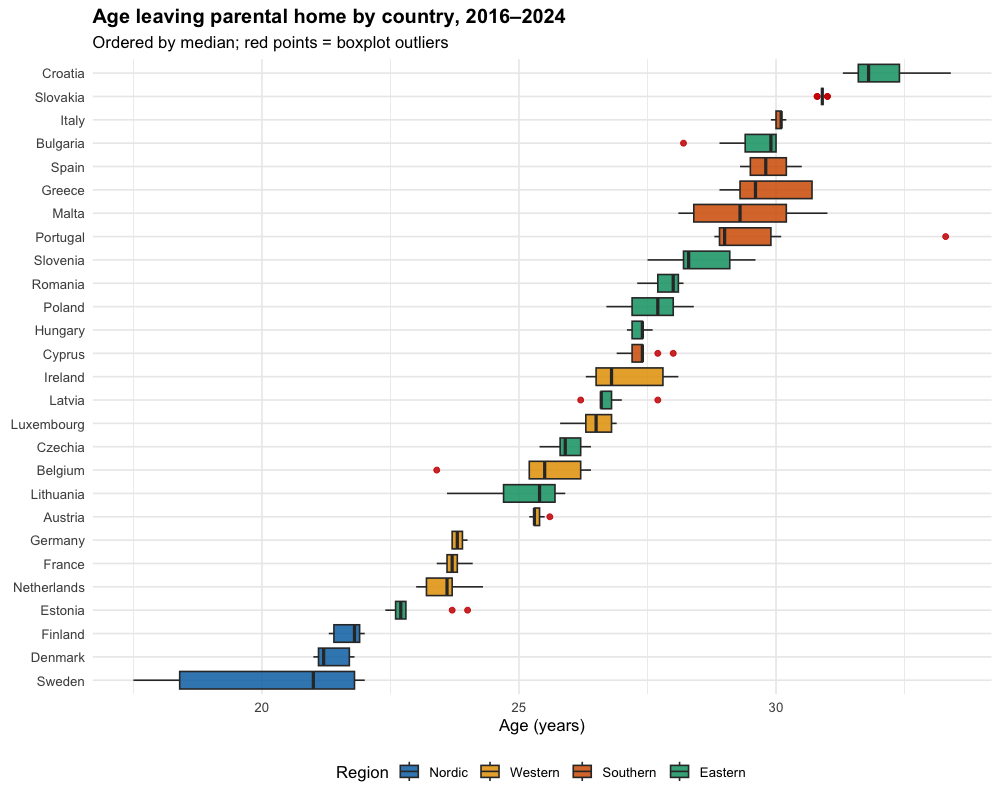

In [7]:
# Country boxplots ordered by median, coloured by region
p <- ggplot(d, aes(fct_reorder(country, leave_age_total, median), leave_age_total, fill = region)) +
  geom_boxplot(outlier.colour = "red3", alpha = .85) + coord_flip() +
  scale_fill_manual(values = reg_cols) +
  labs(title = "Age leaving parental home by country, 2016–2024", subtitle = "Ordered by median; red points = boxplot outliers",
       x = NULL, y = "Age (years)", fill = "Region")
save_fig(p, "02_country_boxplot.png", 9, 8); options(repr.plot.height = 8); p

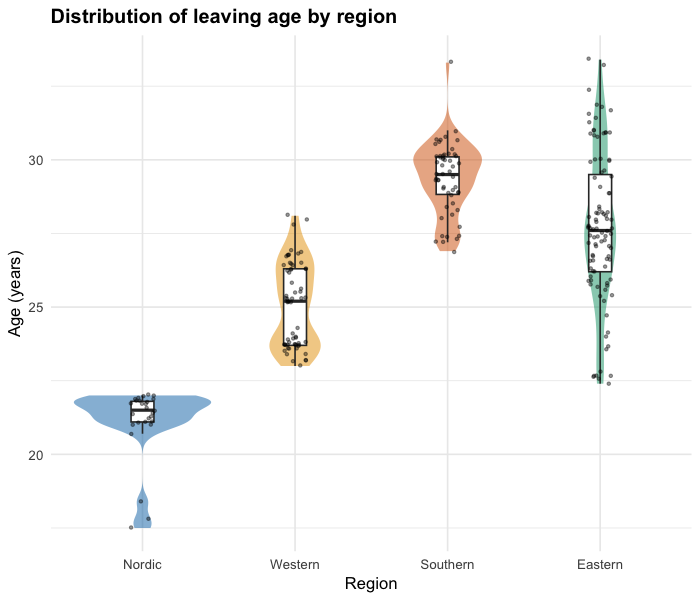

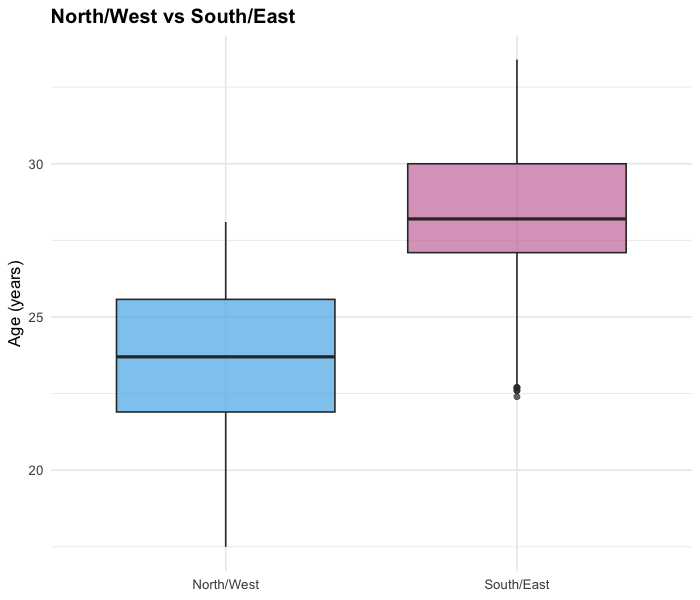

In [8]:
options(repr.plot.height = 6)
# Region distributions (violin + boxplot + country-year points)
p <- ggplot(d, aes(region, leave_age_total, fill = region)) +
  geom_violin(alpha = .5, colour = NA) + geom_boxplot(width = .15, fill = "white", outlier.shape = NA) +
  geom_jitter(width = .08, size = .8, alpha = .4) +
  scale_fill_manual(values = reg_cols, guide = "none") +
  labs(title = "Distribution of leaving age by region", x = "Region", y = "Age (years)")
p2 <- ggplot(d, aes(region_2groups, leave_age_total, fill = region_2groups)) +
  geom_boxplot(alpha = .7) + scale_fill_manual(values = c("North/West" = "#56B4E9", "South/East" = "#CC79A7"), guide = "none") +
  labs(title = "North/West vs South/East", x = NULL, y = "Age (years)")
save_fig(p, "03_region_violin.png", 8, 5); save_fig(p2, "03b_region2_box.png", 6, 5)
options(repr.plot.width = 7); p; p2; options(repr.plot.width = 10)

**Findings**

- Highest country means: Croatia (32.08), Slovakia (30.90), Italy (30.07). Lowest: Sweden (20.30), Denmark (21.38), Finland (21.69) – a gap of ~12 years between extremes.
- Region means: Nordic 21.12 < Western 25.07 < Eastern 27.70 < Southern 29.37. Eastern is by far the most heterogeneous region (variance 6.44, SD 2.54, range 22.4–33.4; from Estonia to Croatia).
- North/West averages 23.88 vs 28.29 for South/East (≈ 4.4 years higher), with similar spread (variance 5.13 vs 5.31).
- Differences between countries dominate differences over time: most countries have a 9-year SD below 1 year; the largest are Sweden (1.86) and Portugal (1.44), i.e. the outliers from Section 1.

## 3. Gender

In [9]:
# Long format: one row per country-year-sex
g <- d %>% select(country, region, year, Men = leave_age_men, Women = leave_age_women) %>%
  pivot_longer(c(Men, Women), names_to = "sex", values_to = "age")
cat("Overall (all country-years):\n"); tab(desc(g, age, sex))
cat("Per year:\n"); tab(desc(g, age, year, sex))

Overall (all country-years):


|sex   |   n|  mean| median| variance|   sd|  min|  max|   p25|  p75|   p90|
|:-----|---:|-----:|------:|--------:|----:|----:|----:|-----:|----:|-----:|
|Men   | 243| 27.62|   27.8|    11.68| 3.42| 17.5| 34.8| 24.75| 30.3| 31.88|
|Women | 243| 25.67|   25.8|     8.31| 2.88| 17.6| 32.5| 23.20| 28.0| 29.40|

Per year:


| year|sex   |  n|  mean| median| variance|   sd|  min|  max|   p25|   p75|   p90|
|----:|:-----|--:|-----:|------:|--------:|----:|----:|----:|-----:|-----:|-----:|
| 2016|Men   | 27| 27.73|   27.8|    10.88| 3.30| 20.8| 33.0| 25.50| 30.35| 31.58|
| 2016|Women | 27| 25.66|   25.9|     7.51| 2.74| 20.6| 30.1| 23.70| 27.45| 29.28|
| 2017|Men   | 27| 27.63|   28.1|    11.18| 3.34| 21.1| 33.2| 24.80| 30.30| 31.36|
| 2017|Women | 27| 25.60|   25.8|     7.78| 2.79| 20.8| 30.5| 23.00| 27.60| 29.22|
| 2018|Men   | 27| 27.48|   27.3|    12.73| 3.57| 18.4| 33.4| 25.25| 30.50| 31.40|
| 2018|Women | 27| 25.49|   25.7|     8.52| 2.92| 18.5| 29.9| 23.65| 27.70| 29.26|
| 2019|Men   | 27| 27.39|   28.1|    12.73| 3.57| 18.0| 33.4| 25.15| 30.00| 31.44|
| 2019|Women | 27| 25.39|   26.0|     8.85| 2.98| 17.6| 29.9| 23.75| 27.70| 28.86|
| 2020|Men   | 27| 27.61|   27.9|    13.68| 3.70| 17.5| 34.0| 25.55| 30.65| 31.52|
| 2020|Women | 27| 25.64|   25.9|     9.40| 3.07| 17.6| 30.8| 24.00| 28.10| 29.12|
| 2021|Men   | 27| 28.00|   28.3|    13.04| 3.61| 22.0| 34.8| 25.40| 30.90| 31.96|
| 2021|Women | 27| 26.03|   26.0|     9.91| 3.15| 20.6| 32.5| 23.60| 28.20| 29.54|
| 2022|Men   | 27| 27.76|   28.2|    12.39| 3.52| 21.8| 34.8| 25.05| 30.65| 31.94|
| 2022|Women | 27| 25.87|   25.7|     9.35| 3.06| 20.5| 31.9| 23.35| 28.10| 29.52|
| 2023|Men   | 27| 27.59|   28.0|    11.27| 3.36| 22.0| 33.4| 24.85| 30.15| 32.00|
| 2023|Women | 27| 25.77|   25.8|     8.29| 2.88| 20.7| 30.3| 23.20| 28.25| 29.28|
| 2024|Men   | 27| 27.35|   27.6|    10.47| 3.24| 22.1| 32.7| 24.40| 29.80| 31.46|
| 2024|Women | 27| 25.55|   25.7|     7.42| 2.72| 20.8| 29.8| 23.05| 27.70| 29.28|

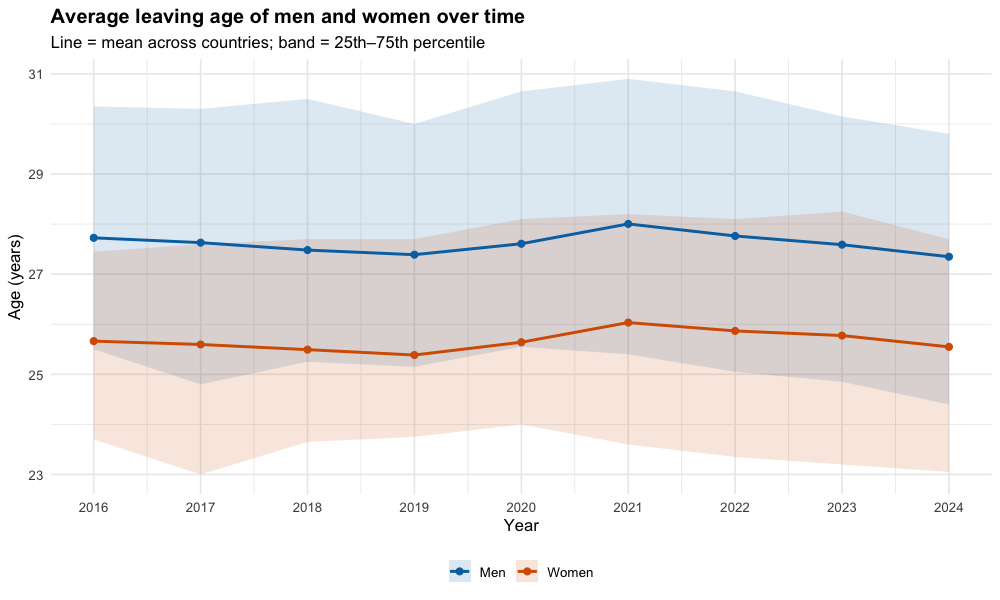

In [10]:
# Men vs women over time: EU mean line + interquartile band across countries
gy <- desc(g, age, year, sex)
p <- ggplot(gy, aes(year, mean, colour = sex, fill = sex)) +
  geom_ribbon(aes(ymin = p25, ymax = p75), alpha = .15, colour = NA) +
  geom_line(linewidth = 1) + geom_point(size = 2) +
  scale_x_continuous(breaks = 2016:2024) +
  scale_colour_manual(values = c(Men = "#0072B2", Women = "#D55E00")) +
  scale_fill_manual(values = c(Men = "#0072B2", Women = "#D55E00")) +
  labs(title = "Average leaving age of men and women over time", subtitle = "Line = mean across countries; band = 25th–75th percentile",
       x = "Year", y = "Age (years)", colour = NULL, fill = NULL)
save_fig(p, "04_gender_time.png"); p

Paired t-test on country means (men - women):


# A tibble: 1 × 5
  estimate statistic  p.value conf.low conf.high
     <dbl>     <dbl>    <dbl>    <dbl>     <dbl>
1     1.95      10.6 6.37e-11     1.57      2.33


Country-years where women leave later than men: 3 


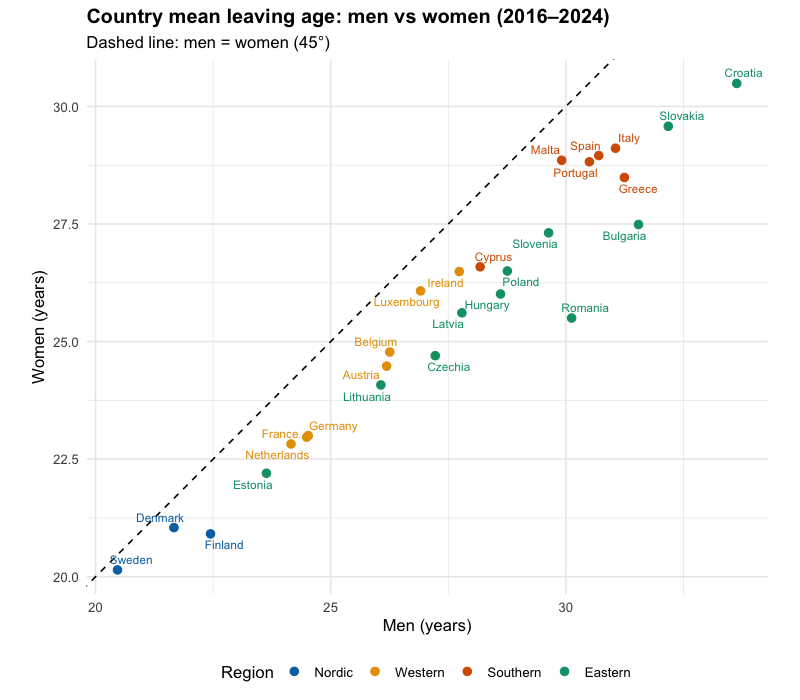

In [11]:
# Country means: men vs women (points below the 45° line = women leave earlier)
cm <- d %>% group_by(country, region) %>% summarise(men = mean(leave_age_men), women = mean(leave_age_women), .groups = "drop")
p <- ggplot(cm, aes(men, women, colour = region)) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed") +
  geom_point(size = 2.5) + geom_text_repel(aes(label = country), size = 3, show.legend = FALSE, max.overlaps = 30) +
  coord_equal() + scale_colour_manual(values = reg_cols) +
  labs(title = "Country mean leaving age: men vs women (2016–2024)", subtitle = "Dashed line: men = women (45°)",
       x = "Men (years)", y = "Women (years)", colour = "Region")
save_fig(p, "05_gender_scatter.png", 8, 7); options(repr.plot.width = 8, repr.plot.height = 7); p
cat("Paired t-test on country means (men - women):\n"); print(tidy(t.test(cm$men, cm$women, paired = TRUE)) %>% select(estimate, statistic, p.value, conf.low, conf.high))
cat("Country-years where women leave later than men:", sum(d$gender_gap < 0), "\n")

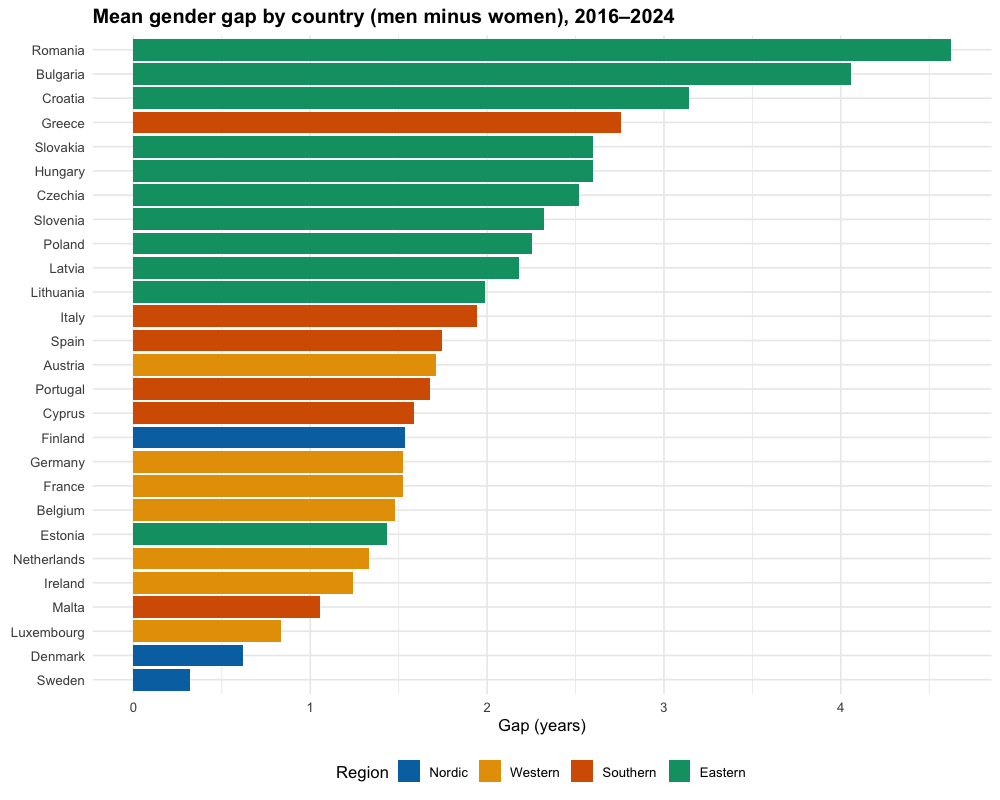

Gap by region:


|region   |  n| mean| median|   sd|  min| max|
|:--------|--:|----:|------:|----:|----:|---:|
|Nordic   | 27| 0.83|    0.6| 0.56| -0.1| 1.7|
|Western  | 63| 1.38|    1.4| 0.33|  0.4| 2.1|
|Southern | 54| 1.79|    1.8| 0.72| -1.2| 3.6|
|Eastern  | 99| 2.70|    2.5| 0.94|  1.0| 4.9|

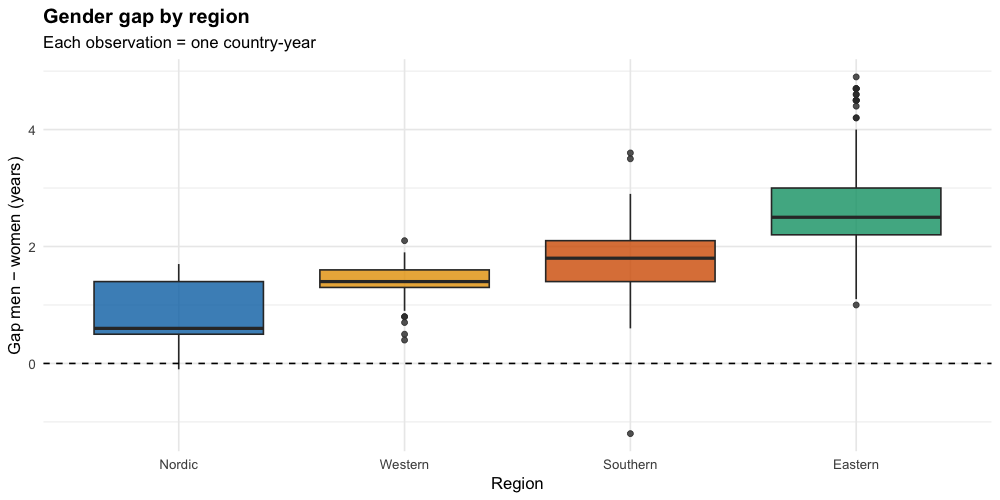

In [12]:
options(repr.plot.width = 10, repr.plot.height = 6)
# Gender gap (men - women) by country and by region
gap_c <- d %>% group_by(country, region) %>% summarise(gap = mean(gender_gap), .groups = "drop")
p <- ggplot(gap_c, aes(fct_reorder(country, gap), gap, fill = region)) +
  geom_col() + coord_flip() + scale_fill_manual(values = reg_cols) +
  labs(title = "Mean gender gap by country (men minus women), 2016–2024", x = NULL, y = "Gap (years)", fill = "Region")
save_fig(p, "06_gap_country.png", 9, 8)
p2 <- ggplot(d, aes(region, gender_gap, fill = region)) +
  geom_boxplot(alpha = .8) + geom_hline(yintercept = 0, linetype = "dashed") +
  scale_fill_manual(values = reg_cols, guide = "none") +
  labs(title = "Gender gap by region", subtitle = "Each observation = one country-year", x = "Region", y = "Gap men − women (years)")
save_fig(p2, "07_gap_region.png", 8, 5)
options(repr.plot.height = 8); p; options(repr.plot.height = 5); p2
cat("Gap by region:\n"); tab(desc(d, gender_gap, region) %>% select(region, n, mean, median, sd, min, max))

**Findings**

- Men leave later than women: mean 27.62 vs 25.67 (median 27.8 vs 25.8). The paired difference of country means is 1.95 years (95% CI 1.57–2.33, p ≈ 6e-11). Men are also more dispersed (variance 11.68 vs 8.31).
- Both series are flat over time. The yearly mean gap goes from 2.07 (2016) to 1.80 (2024); men 27.73 → 27.35, women 25.66 → 25.55.
- Women leave later than men in only 3 of 243 country-years (Sweden 2018 and 2020, Malta 2023). Almost all country means lie below the 45° line.
- The gap is regional: Nordic 0.83, Western 1.38, Southern 1.79, Eastern 2.70 years. Largest country gaps: Romania (4.62), Bulgaria (4.06), Croatia (3.14); smallest: Sweden (0.32), Denmark (0.62), Luxembourg (0.83).

## 4. Rankings
Rank 1 = latest leavers (highest age). Ties share the lowest rank.

In [13]:
rk <- d %>% group_by(year) %>% mutate(rank = rank(-leave_age_total, ties.method = "min")) %>% ungroup()
rk_wide <- rk %>% select(country, region, year, rank) %>% pivot_wider(names_from = year, values_from = rank, names_prefix = "rank_") %>%
  arrange(rank_2024)
tab(rk_wide, 0)

|country     |region   | rank_2016| rank_2017| rank_2018| rank_2019| rank_2020| rank_2021| rank_2022| rank_2023| rank_2024|
|:-----------|:--------|---------:|---------:|---------:|---------:|---------:|---------:|---------:|---------:|---------:|
|Croatia     |Eastern  |         1|         1|         1|         1|         1|         2|         1|         1|         1|
|Slovakia    |Eastern  |         2|         3|         2|         2|         2|         3|         2|         2|         2|
|Greece      |Southern |         7|         5|         7|         7|         8|         4|         3|         3|         3|
|Italy       |Southern |         4|         4|         4|         3|         3|         7|         6|         5|         4|
|Spain       |Southern |         5|         6|         6|         5|         6|         5|         4|         4|         5|
|Portugal    |Southern |         8|         7|         8|         7|         4|         1|         5|         8|         6|
|Slovenia    |Eastern  |         9|         9|         9|        10|        12|         8|         8|         7|         6|
|Bulgaria    |Eastern  |         5|         8|         5|         4|         4|         6|         6|         5|         8|
|Malta       |Southern |         3|         2|         3|         6|         6|        10|         9|         9|         9|
|Romania     |Eastern  |        10|        10|         9|         9|        10|        11|        12|        11|        10|
|Cyprus      |Southern |        14|        12|        12|        12|        14|        13|        11|        12|        11|
|Hungary     |Eastern  |        13|        12|        12|        11|        12|        14|        13|        14|        12|
|Luxembourg  |Western  |        16|        16|        17|        16|        16|        15|        15|        15|        13|
|Ireland     |Western  |        15|        16|        15|        14|         9|        12|        14|        10|        14|
|Poland      |Eastern  |        11|        11|        11|        13|        11|         9|        10|        13|        15|
|Latvia      |Eastern  |        12|        14|        14|        15|        15|        16|        15|        17|        16|
|Belgium     |Western  |        20|        24|        20|        20|        19|        17|        17|        16|        17|
|Czechia     |Eastern  |        17|        15|        16|        18|        17|        18|        18|        18|        18|
|Austria     |Western  |        19|        19|        19|        19|        19|        19|        19|        19|        19|
|Germany     |Western  |        23|        21|        21|        21|        23|        21|        21|        21|        20|
|Lithuania   |Eastern  |        18|        18|        18|        17|        18|        20|        20|        20|        21|
|France      |Western  |        22|        20|        21|        23|        22|        22|        22|        22|        22|
|Netherlands |Western  |        23|        23|        21|        21|        21|        23|        23|        23|        23|
|Estonia     |Eastern  |        21|        21|        24|        24|        24|        24|        24|        24|        24|
|Sweden      |Nordic   |        27|        27|        27|        27|        27|        25|        26|        25|        25|
|Denmark     |Nordic   |        26|        26|        26|        26|        26|        26|        25|        25|        26|
|Finland     |Nordic   |        25|        25|        25|        25|        25|        27|        27|        27|        27|

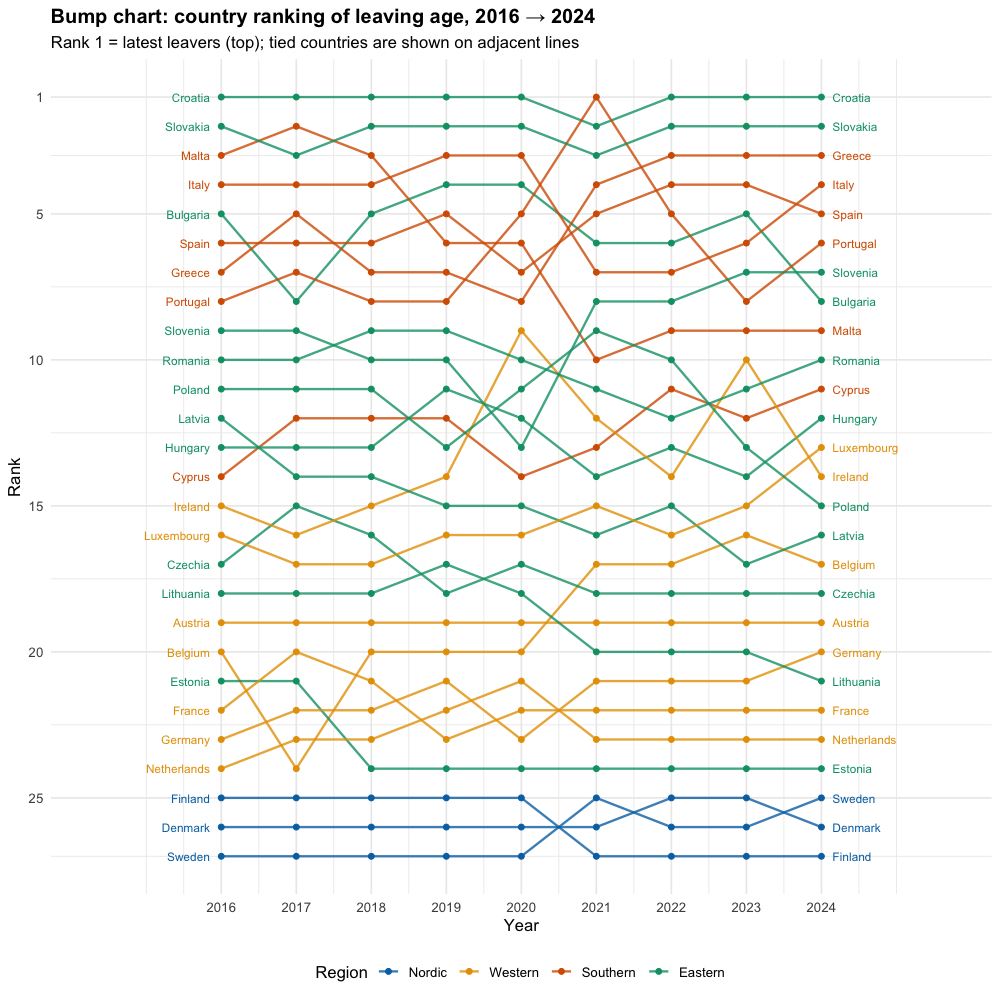

In [14]:
options(repr.plot.height = 10)
# Bump chart (all years; labels at 2016 and 2024)
rk <- rk %>% group_by(year) %>% mutate(rank_plot = rank(-leave_age_total, ties.method = "first")) %>% ungroup()  # ties split only for plotting
p <- ggplot(rk, aes(year, rank_plot, group = country, colour = region)) +
  geom_line(linewidth = .8, alpha = .8) + geom_point(size = 1.6) +
  geom_text(data = filter(rk, year == 2016), aes(label = country), hjust = 1, nudge_x = -.15, size = 3, show.legend = FALSE) +
  geom_text(data = filter(rk, year == 2024), aes(label = country), hjust = 0, nudge_x = .15, size = 3, show.legend = FALSE) +
  scale_y_reverse(breaks = c(1, 5, 10, 15, 20, 25)) + scale_x_continuous(breaks = 2016:2024, limits = c(2014.3, 2025.7)) +
  scale_colour_manual(values = reg_cols) +
  labs(title = "Bump chart: country ranking of leaving age, 2016 → 2024", subtitle = "Rank 1 = latest leavers (top); tied countries are shown on adjacent lines",
       x = "Year", y = "Rank", colour = "Region")
save_fig(p, "08_bump_chart.png", 11, 10); p

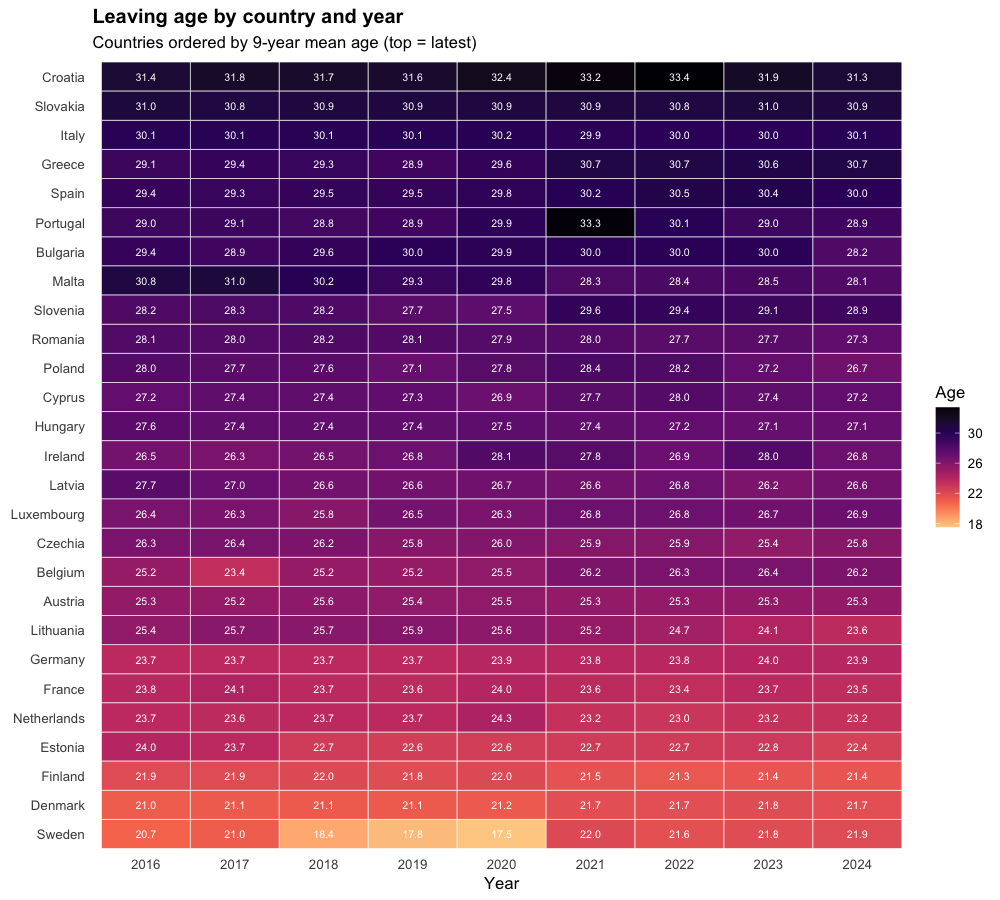

In [15]:
options(repr.plot.height = 9)
# Heatmap: age by country and year (countries ordered by mean age)
p <- ggplot(d, aes(factor(year), fct_reorder(country, leave_age_total, mean), fill = leave_age_total)) +
  geom_tile(colour = "white") + geom_text(aes(label = sprintf("%.1f", leave_age_total)), size = 2.7, colour = "white") +
  scale_fill_viridis_c(option = "magma", direction = -1, end = .9, name = "Age") +
  labs(title = "Leaving age by country and year", subtitle = "Countries ordered by 9-year mean age (top = latest)", x = "Year", y = NULL) +
  theme(legend.position = "right", panel.grid = element_blank())
save_fig(p, "09_heatmap.png", 10, 9); p

In [16]:
# Rank change 2016 -> 2024 (positive = moved up, i.e. now leaves relatively later)
chg <- rk %>% filter(year %in% c(2016, 2024)) %>%
  select(country, region, year, rank, age = leave_age_total) %>%
  pivot_wider(names_from = year, values_from = c(rank, age)) %>%
  mutate(rank_change = rank_2016 - rank_2024, age_change = age_2024 - age_2016) %>% arrange(desc(rank_change))
cat("Full table:\n"); tab(chg, 1)
cat("5 biggest risers:\n"); tab(head(chg, 5), 1)
cat("5 biggest fallers:\n"); tab(tail(chg, 5) %>% arrange(rank_change), 1)

# Stability: Spearman correlation (on ages = rank correlation with proper tie handling)
w <- d %>% select(country, year, leave_age_total) %>% pivot_wider(names_from = year, values_from = leave_age_total)
ct <- suppressWarnings(cor.test(w$`2016`, w$`2024`, method = "spearman", exact = FALSE))
cat(sprintf("\nSpearman rho (2016 vs 2024) = %.3f, p = %.2g\n", ct$estimate, ct$p.value))
tab(data.frame(year = 2017:2024, rho_vs_2016 = sapply(as.character(2017:2024), function(y) cor(w$`2016`, w[[y]], method = "spearman"))), 3)

Full table:


|country     |region   | rank_2016| rank_2024| age_2016| age_2024| rank_change| age_change|
|:-----------|:--------|---------:|---------:|--------:|--------:|-----------:|----------:|
|Greece      |Southern |         7|         3|     29.1|     30.7|           4|        1.6|
|Belgium     |Western  |        20|        17|     25.2|     26.2|           3|        1.0|
|Cyprus      |Southern |        14|        11|     27.2|     27.2|           3|        0.0|
|Germany     |Western  |        23|        20|     23.7|     23.9|           3|        0.2|
|Luxembourg  |Western  |        16|        13|     26.4|     26.9|           3|        0.5|
|Slovenia    |Eastern  |         9|         6|     28.2|     28.9|           3|        0.7|
|Portugal    |Southern |         8|         6|     29.0|     28.9|           2|       -0.1|
|Sweden      |Nordic   |        27|        25|     20.7|     21.9|           2|        1.2|
|Hungary     |Eastern  |        13|        12|     27.6|     27.1|           1|       -0.5|
|Ireland     |Western  |        15|        14|     26.5|     26.8|           1|        0.3|
|Austria     |Western  |        19|        19|     25.3|     25.3|           0|        0.0|
|Croatia     |Eastern  |         1|         1|     31.4|     31.3|           0|       -0.1|
|Denmark     |Nordic   |        26|        26|     21.0|     21.7|           0|        0.7|
|France      |Western  |        22|        22|     23.8|     23.5|           0|       -0.3|
|Italy       |Southern |         4|         4|     30.1|     30.1|           0|        0.0|
|Netherlands |Western  |        23|        23|     23.7|     23.2|           0|       -0.5|
|Romania     |Eastern  |        10|        10|     28.1|     27.3|           0|       -0.8|
|Slovakia    |Eastern  |         2|         2|     31.0|     30.9|           0|       -0.1|
|Spain       |Southern |         5|         5|     29.4|     30.0|           0|        0.6|
|Czechia     |Eastern  |        17|        18|     26.3|     25.8|          -1|       -0.5|
|Finland     |Nordic   |        25|        27|     21.9|     21.4|          -2|       -0.5|
|Bulgaria    |Eastern  |         5|         8|     29.4|     28.2|          -3|       -1.2|
|Estonia     |Eastern  |        21|        24|     24.0|     22.4|          -3|       -1.6|
|Lithuania   |Eastern  |        18|        21|     25.4|     23.6|          -3|       -1.8|
|Latvia      |Eastern  |        12|        16|     27.7|     26.6|          -4|       -1.1|
|Poland      |Eastern  |        11|        15|     28.0|     26.7|          -4|       -1.3|
|Malta       |Southern |         3|         9|     30.8|     28.1|          -6|       -2.7|

5 biggest risers:


|country    |region   | rank_2016| rank_2024| age_2016| age_2024| rank_change| age_change|
|:----------|:--------|---------:|---------:|--------:|--------:|-----------:|----------:|
|Greece     |Southern |         7|         3|     29.1|     30.7|           4|        1.6|
|Belgium    |Western  |        20|        17|     25.2|     26.2|           3|        1.0|
|Cyprus     |Southern |        14|        11|     27.2|     27.2|           3|        0.0|
|Germany    |Western  |        23|        20|     23.7|     23.9|           3|        0.2|
|Luxembourg |Western  |        16|        13|     26.4|     26.9|           3|        0.5|

5 biggest fallers:


|country   |region   | rank_2016| rank_2024| age_2016| age_2024| rank_change| age_change|
|:---------|:--------|---------:|---------:|--------:|--------:|-----------:|----------:|
|Malta     |Southern |         3|         9|     30.8|     28.1|          -6|       -2.7|
|Latvia    |Eastern  |        12|        16|     27.7|     26.6|          -4|       -1.1|
|Poland    |Eastern  |        11|        15|     28.0|     26.7|          -4|       -1.3|
|Estonia   |Eastern  |        21|        24|     24.0|     22.4|          -3|       -1.6|
|Lithuania |Eastern  |        18|        21|     25.4|     23.6|          -3|       -1.8|


Spearman rho (2016 vs 2024) = 0.949, p = 5e-14


|     | year| rho_vs_2016|
|:----|----:|-----------:|
|2017 | 2017|       0.984|
|2018 | 2018|       0.993|
|2019 | 2019|       0.983|
|2020 | 2020|       0.969|
|2021 | 2021|       0.942|
|2022 | 2022|       0.959|
|2023 | 2023|       0.950|
|2024 | 2024|       0.949|

**Findings**

- Rankings are very stable: Spearman ρ between 2016 and 2024 is 0.949 (p ≈ 5e-14). Against 2016, the correlation never falls below 0.94 in any later year.
- The extremes barely move: Croatia is #1 in 8 of 9 years (and in 2016 and 2024) and Slovakia #2 in 2016 and 2024; Finland, Denmark and Sweden occupy ranks 25–27 in 2024.
- Biggest risers 2016→2024: Greece (7 → 3, +1.6 years), then Belgium, Cyprus, Germany, Luxembourg and Slovenia (+3 ranks each). Biggest fallers: Malta (3 → 9, −2.7 years), Latvia and Poland (−4), Estonia and Lithuania (−3).
- Most of the fallers are Eastern countries whose leaving age dropped by 1.1–1.8 years; the heatmap shows the dark (late) block is Croatia/Slovakia/Southern Europe and the light (early) block is the Nordics. Portugal's one-year jump to rank 1 in 2021 is the outlier from Section 1.

## 5. Overall trend

### 5.1 EU mean and median per year (±1 SD band)
"Significant" years: for each year *y* we regress age on country fixed effects plus an indicator `year == y`. The coefficient is how far year *y* sits above/below the other years **within the same countries**; we report the raw p-value and a Holm-adjusted one (9 tests).

In [17]:
eu <- d %>% group_by(year) %>% summarise(mean = mean(leave_age_total), median = median(leave_age_total), sd = sd(leave_age_total))
tab(eu)

yr_test <- bind_rows(lapply(sort(unique(d$year)), function(y) {
  r <- tidy(lm(leave_age_total ~ country + I(year == y), data = d)) %>% filter(grepl("year", term))
  tibble(year = y, effect = r$estimate, se = r$std.error, p_value = r$p.value)
})) %>% mutate(p_holm = p.adjust(p_value, "holm"))
tab(yr_test, 3)
sig <- yr_test %>% filter(p_value < 0.05) %>% left_join(eu, by = "year")
cat("Years with raw p < 0.05:", sig$year, "\n")

| year|  mean| median|   sd|
|----:|-----:|------:|----:|
| 2016| 26.70|   27.2| 3.00|
| 2017| 26.61|   27.0| 3.03|
| 2018| 26.51|   26.6| 3.22|
| 2019| 26.42|   26.8| 3.25|
| 2020| 26.64|   26.9| 3.37|
| 2021| 27.03|   27.4| 3.36|
| 2022| 26.84|   26.9| 3.26|
| 2023| 26.69|   27.1| 3.07|
| 2024| 26.47|   26.8| 2.96|

| year| effect|    se| p_value| p_holm|
|----:|------:|-----:|-------:|------:|
| 2016|  0.048| 0.141|   0.733|  1.000|
| 2017| -0.048| 0.141|   0.735|  1.000|
| 2018| -0.164| 0.140|   0.243|  1.000|
| 2019| -0.269| 0.140|   0.056|  0.445|
| 2020| -0.019| 0.141|   0.895|  1.000|
| 2021|  0.423| 0.138|   0.002|  0.022|
| 2022|  0.202| 0.140|   0.150|  0.900|
| 2023|  0.040| 0.141|   0.777|  1.000|
| 2024| -0.214| 0.140|   0.127|  0.890|

Years with raw p < 0.05: 2021 


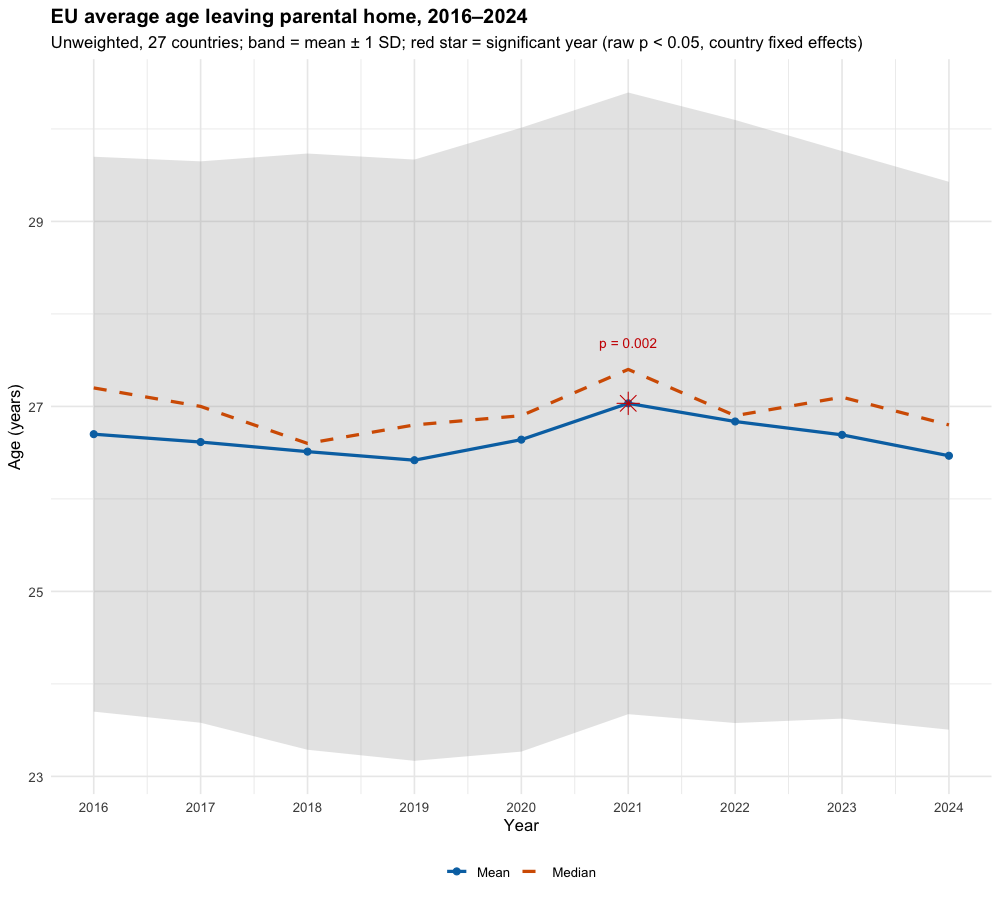

In [18]:
p <- ggplot(eu, aes(year)) +
  geom_ribbon(aes(ymin = mean - sd, ymax = mean + sd), fill = "grey60", alpha = .25) +
  geom_line(aes(y = mean, colour = "Mean"), linewidth = 1.1) + geom_point(aes(y = mean, colour = "Mean"), size = 2) +
  geom_line(aes(y = median, colour = "Median"), linewidth = 1.1, linetype = "dashed") +
  geom_point(data = sig, aes(y = mean), shape = 8, size = 5, colour = "red3") +
  geom_text(data = sig, aes(y = mean + 0.6, label = sprintf("p = %.3f", p_value)), vjust = 0, colour = "red3", size = 3.5) +
  scale_x_continuous(breaks = 2016:2024) + scale_colour_manual(values = c(Mean = "#0072B2", Median = "#D55E00")) +
  labs(title = "EU average age leaving parental home, 2016–2024", subtitle = "Unweighted, 27 countries; band = mean ± 1 SD; red star = significant year (raw p < 0.05, country fixed effects)",
       x = "Year", y = "Age (years)", colour = NULL)
save_fig(p, "10_eu_trend.png"); p

### 5.2 Trend by region and per country

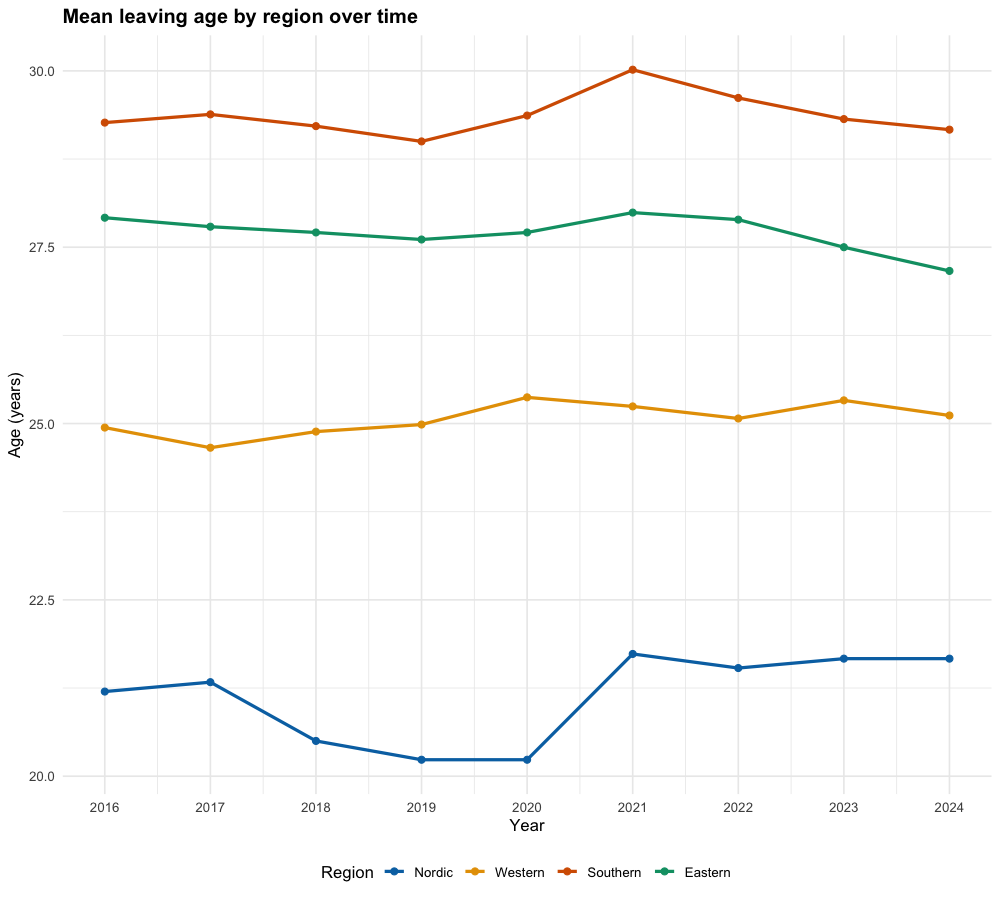

In [19]:
reg_y <- d %>% group_by(region, year) %>% summarise(mean = mean(leave_age_total), .groups = "drop")
p <- ggplot(reg_y, aes(year, mean, colour = region)) + geom_line(linewidth = 1.1) + geom_point(size = 2) +
  scale_x_continuous(breaks = 2016:2024) + scale_colour_manual(values = reg_cols) +
  labs(title = "Mean leaving age by region over time", x = "Year", y = "Age (years)", colour = "Region")
save_fig(p, "11_region_trend.png"); p

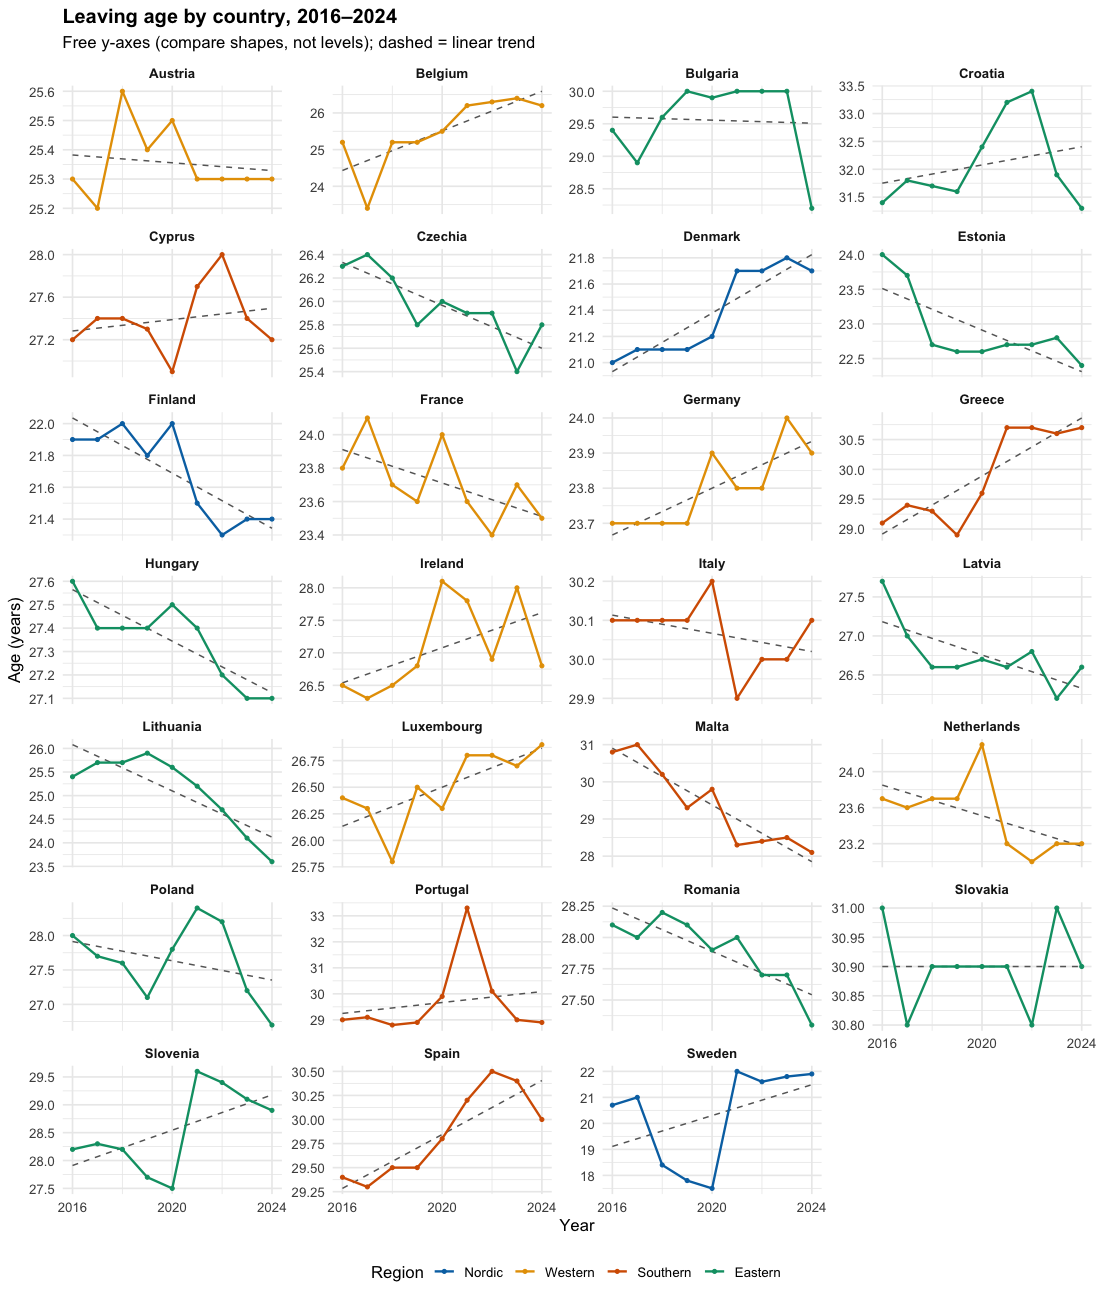

In [20]:
options(repr.plot.width = 11, repr.plot.height = 13)
p <- ggplot(d, aes(year, leave_age_total, colour = region)) +
  geom_smooth(method = "lm", se = FALSE, colour = "grey40", linetype = "dashed", linewidth = .5, formula = y ~ x) +
  geom_line(linewidth = .8) + geom_point(size = 1) +
  facet_wrap(~country, ncol = 4, scales = "free_y") + scale_x_continuous(breaks = c(2016, 2020, 2024)) +
  scale_colour_manual(values = reg_cols) +
  labs(title = "Leaving age by country, 2016–2024", subtitle = "Free y-axes (compare shapes, not levels); dashed = linear trend",
       x = "Year", y = "Age (years)", colour = "Region") + theme(strip.text = element_text(face = "bold"))
save_fig(p, "12_country_facets.png", 11, 13); p

### 5.3 Linear trends (age ~ year) per country and for the EU
Slope = change in years of age per calendar year. EU = regression on the yearly EU mean (n = 9). `p_BH` is the Benjamini–Hochberg adjustment across the 27 countries.

In [21]:
slopes <- d %>% group_by(country, region) %>%
  group_modify(~ tidy(lm(leave_age_total ~ year, data = .x), conf.int = TRUE) %>% filter(term == "year")) %>% ungroup() %>%
  mutate(p_BH = p.adjust(p.value, "BH")) %>% arrange(desc(estimate))
eu_fit <- tidy(lm(mean ~ year, data = eu), conf.int = TRUE) %>% filter(term == "year")
slope_tab <- bind_rows(mutate(eu_fit, country = "EU (mean of countries)", region = NA), slopes) %>%
  transmute(country, region = as.character(region), slope = estimate, std.error, p_value = p.value, p_BH, change_8y = 8 * estimate)
tab(slope_tab, 3)
cat("Countries with p < 0.05:", sum(slopes$p.value < .05), "| with BH-adjusted p < 0.05:", sum(slopes$p_BH < .05),
    "| positive slopes:", sum(slopes$estimate > 0), "of", nrow(slopes), "\n")

|country                |region   |  slope| std.error| p_value|  p_BH| change_8y|
|:----------------------|:--------|------:|---------:|-------:|-----:|---------:|
|EU (mean of countries) |NA       |  0.009|     0.026|   0.729|    NA|     0.076|
|Sweden                 |Nordic   |  0.297|     0.231|   0.240| 0.342|     2.373|
|Belgium                |Western  |  0.270|     0.081|   0.012| 0.030|     2.160|
|Greece                 |Southern |  0.243|     0.053|   0.003| 0.018|     1.947|
|Slovenia               |Eastern  |  0.158|     0.083|   0.097| 0.161|     1.267|
|Spain                  |Southern |  0.140|     0.033|   0.004| 0.018|     1.120|
|Ireland                |Western  |  0.135|     0.081|   0.141| 0.212|     1.080|
|Denmark                |Nordic   |  0.112|     0.019|   0.001| 0.008|     0.893|
|Portugal               |Southern |  0.105|     0.195|   0.606| 0.682|     0.840|
|Luxembourg             |Western  |  0.092|     0.033|   0.027| 0.056|     0.733|
|Croatia                |Eastern  |  0.082|     0.101|   0.444| 0.545|     0.653|
|Germany                |Western  |  0.033|     0.009|   0.007| 0.020|     0.267|
|Cyprus                 |Southern |  0.027|     0.042|   0.547| 0.642|     0.213|
|Slovakia               |Eastern  |  0.000|     0.010|   1.000| 1.000|     0.000|
|Austria                |Western  | -0.007|     0.017|   0.705| 0.761|    -0.053|
|Bulgaria               |Eastern  | -0.012|     0.087|   0.897| 0.932|    -0.093|
|Italy                  |Southern | -0.012|     0.011|   0.329| 0.444|    -0.093|
|France                 |Western  | -0.050|     0.025|   0.084| 0.151|    -0.400|
|Hungary                |Eastern  | -0.055|     0.012|   0.003| 0.018|    -0.440|
|Poland                 |Eastern  | -0.070|     0.071|   0.358| 0.460|    -0.560|
|Netherlands            |Western  | -0.085|     0.045|   0.102| 0.161|    -0.680|
|Finland                |Nordic   | -0.087|     0.022|   0.005| 0.018|    -0.693|
|Romania                |Eastern  | -0.087|     0.021|   0.004| 0.018|    -0.693|
|Czechia                |Eastern  | -0.092|     0.024|   0.006| 0.018|    -0.733|
|Latvia                 |Eastern  | -0.107|     0.040|   0.033| 0.063|    -0.853|
|Estonia                |Eastern  | -0.150|     0.050|   0.020| 0.046|    -1.200|
|Lithuania              |Eastern  | -0.245|     0.060|   0.005| 0.018|    -1.960|
|Malta                  |Southern | -0.382|     0.056|   0.000| 0.006|    -3.053|

Countries with p < 0.05: 14 | with BH-adjusted p < 0.05: 12 | positive slopes: 13 of 27 


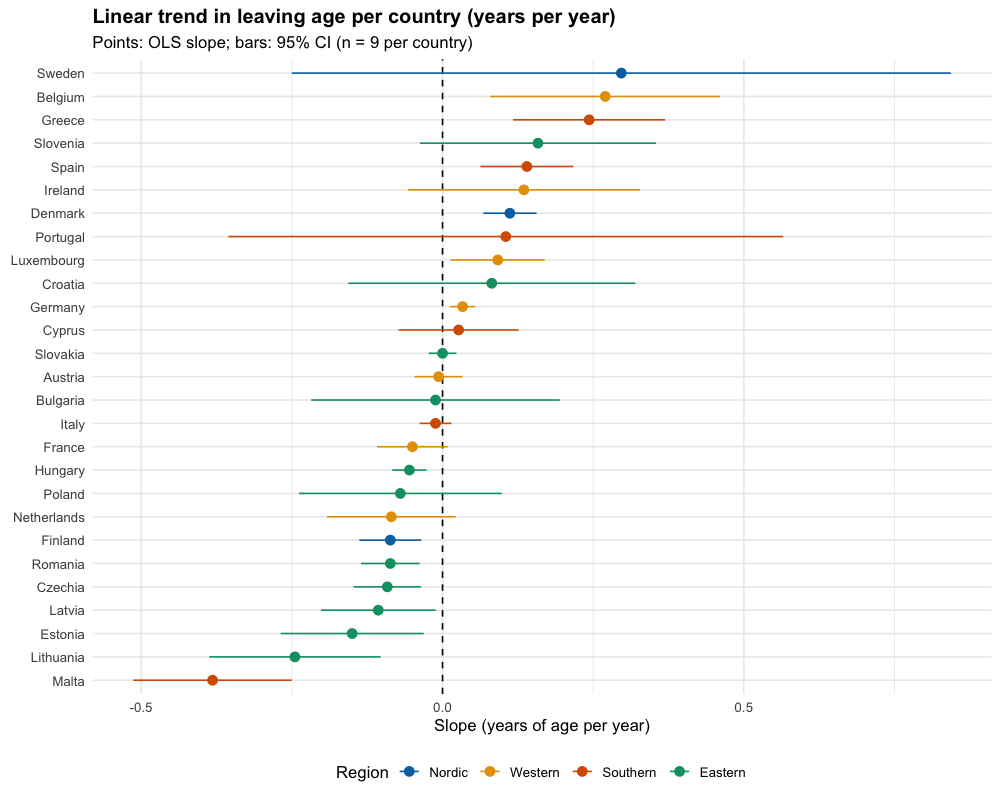

In [22]:
options(repr.plot.width = 10, repr.plot.height = 8)
p <- ggplot(slopes, aes(estimate, fct_reorder(country, estimate), colour = region)) +
  geom_vline(xintercept = 0, linetype = "dashed") + geom_pointrange(aes(xmin = conf.low, xmax = conf.high)) +
  scale_colour_manual(values = reg_cols) +
  labs(title = "Linear trend in leaving age per country (years per year)", subtitle = "Points: OLS slope; bars: 95% CI (n = 9 per country)",
       x = "Slope (years of age per year)", y = NULL, colour = "Region")
save_fig(p, "13_slopes.png", 9, 8); p

### 5.4 Sensitivity: EU trend without outliers
Three versions: all data; the flagged outlier observations removed (Section 1); and Sweden + Portugal dropped completely (keeps the country set constant across years).

In [23]:
eu_summary <- function(df) df %>% group_by(year) %>% summarise(mean = mean(leave_age_total), median = median(leave_age_total))
variants <- list("All data" = d,
                 "Outlier obs. removed" = filter(d, !outlier),
                 "Sweden & Portugal dropped" = filter(d, !country %in% c("Sweden", "Portugal")))
eu_v <- bind_rows(lapply(names(variants), function(n) mutate(eu_summary(variants[[n]]), version = n)))

# Slope comparison
sens <- bind_rows(lapply(names(variants), function(n) {
  e <- eu_v %>% filter(version == n)
  f <- tidy(lm(mean ~ year, data = e), conf.int = TRUE) %>% filter(term == "year")
  tibble(version = n, n_obs = nrow(variants[[n]]), slope = f$estimate, std.error = f$std.error, p_value = f$p.value,
         ci_low = f$conf.low, ci_high = f$conf.high, mean_2016 = e$mean[1], mean_2024 = e$mean[9])
}))
tab(sens, 3)

# Yearly means side by side and max difference vs full data
wide <- eu_v %>% select(year, version, mean) %>% pivot_wider(names_from = version, values_from = mean) %>%
  mutate(diff_outliers_removed = `Outlier obs. removed` - `All data`, diff_SE_PT_dropped = `Sweden & Portugal dropped` - `All data`)
tab(wide, 3)
cat("Max |difference| in yearly mean: outliers removed =", round(max(abs(wide$diff_outliers_removed)), 3),
    "| Sweden & Portugal dropped =", round(max(abs(wide$diff_SE_PT_dropped)), 3), "\n")

|version                   | n_obs|  slope| std.error| p_value| ci_low| ci_high| mean_2016| mean_2024|
|:-------------------------|-----:|------:|---------:|-------:|------:|-------:|---------:|---------:|
|All data                  |   243|  0.009|     0.026|   0.729| -0.053|   0.071|    26.700|    26.467|
|Outlier obs. removed      |   238| -0.017|     0.018|   0.396| -0.060|   0.027|    26.700|    26.467|
|Sweden & Portugal dropped |   225| -0.006|     0.018|   0.757| -0.049|   0.037|    26.848|    26.552|

| year| All data| Outlier obs. removed| Sweden & Portugal dropped| diff_outliers_removed| diff_SE_PT_dropped|
|----:|--------:|--------------------:|-------------------------:|---------------------:|------------------:|
| 2016|   26.700|               26.700|                    26.848|                 0.000|              0.148|
| 2017|   26.615|               26.738|                    26.740|                 0.124|              0.125|
| 2018|   26.511|               26.823|                    26.744|                 0.312|              0.233|
| 2019|   26.419|               26.750|                    26.664|                 0.331|              0.245|
| 2020|   26.641|               26.992|                    26.876|                 0.352|              0.235|
| 2021|   27.033|               26.792|                    26.984|                -0.241|             -0.049|
| 2022|   26.837|               26.837|                    26.916|                 0.000|              0.079|
| 2023|   26.693|               26.693|                    26.796|                 0.000|              0.103|
| 2024|   26.467|               26.467|                    26.552|                 0.000|              0.085|

Max |difference| in yearly mean: outliers removed = 0.352 | Sweden & Portugal dropped = 0.245 


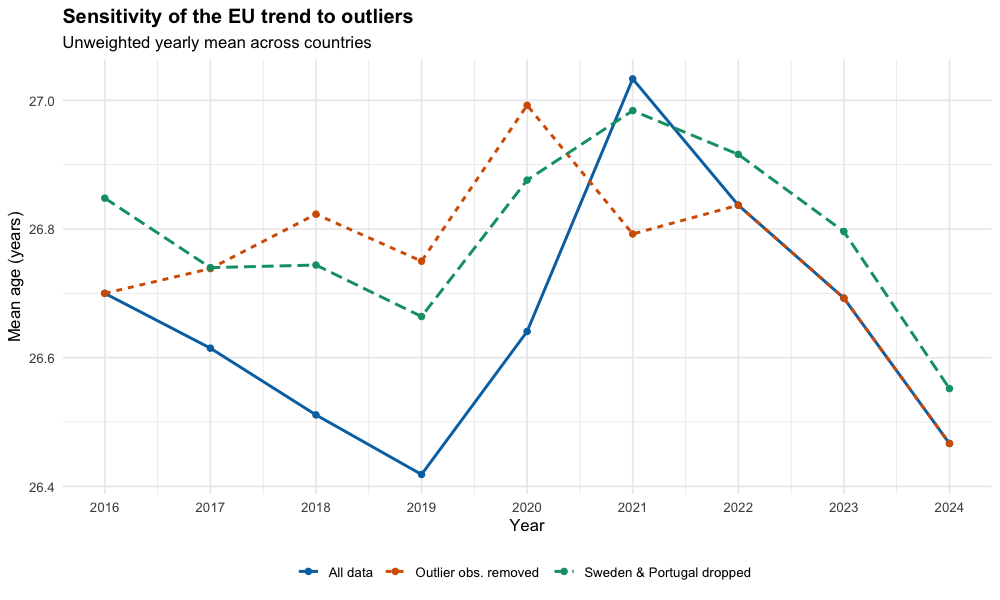

In [24]:
options(repr.plot.height = 6)
p <- ggplot(eu_v, aes(year, mean, colour = version, linetype = version)) +
  geom_line(linewidth = 1) + geom_point(size = 1.8) +
  scale_x_continuous(breaks = 2016:2024) + scale_colour_manual(values = c("#0072B2", "#D55E00", "#009E73")) +
  labs(title = "Sensitivity of the EU trend to outliers", subtitle = "Unweighted yearly mean across countries",
       x = "Year", y = "Mean age (years)", colour = NULL, linetype = NULL)
save_fig(p, "14_sensitivity.png"); p

**Findings**

- There is **no EU-wide trend**: the unweighted EU mean is 26.70 in 2016 and 26.47 in 2024; the linear slope is +0.009 years/year (p = 0.73). The median moves 27.2 → 26.8. The ±1 SD band stays between ~2.96 and 3.37.
- The only year that differs significantly from the others (country fixed effects) is **2021**: +0.42 years (p = 0.002, Holm-adjusted p = 0.022); mean 27.03 vs ~26.4–26.8 in other years. 2019 is borderline (−0.27, p = 0.056, Holm 0.45).
- Country trends diverge: 13 of 27 slopes are positive; 14 are significant at 5% (12 after Benjamini–Hochberg). Rising: Belgium +0.27/yr, Greece +0.24, Spain +0.14, Denmark +0.11. Falling: Malta −0.38/yr, Lithuania −0.25, Estonia −0.15, Czechia/Romania/Finland ≈ −0.09. Regional means rise slightly in Southern/Western countries during 2020–21 and drift down in the East (27.92 → 27.16).
- **Sensitivity:** removing the 5 flagged observations moves the slope from +0.009 to −0.017 (p = 0.40); dropping Sweden and Portugal gives −0.006 (p = 0.76). All CIs include 0. Yearly means change by at most 0.35 years (2018–2020, from Sweden's dip; 2021 −0.24 from Portugal). Outliers matter for individual years but not for the conclusion of a flat trend.

## 6. Summary

- **Levels are structural, change is small.** Leaving age ranges from 20.3 (Sweden) to 32.1 (Croatia) on country averages; region explains much of this (Nordic 21.1, Western 25.1, Eastern 27.7, Southern 29.4; North/West vs South/East ≈ 23.9 vs 28.3).
- **No EU-level trend in 2016–2024:** the EU mean is 26.70 → 26.47 (slope +0.009/yr, p = 0.73); only 2021 stands out significantly (+0.42). Individual countries do move: Malta, Lithuania and Estonia are earlier leavers over time, while Belgium, Greece and Spain are later.
- **Rankings are stable** (Spearman 0.949 between 2016 and 2024). Biggest movers: Greece up (+4 ranks), Malta down (−6).
- **Gender:** men leave ~1.95 years later than women on average, the gap is largest in Eastern Europe (2.70) and smallest in the Nordics (0.83), and it has been roughly stable (2.07 → 1.80).
- **Outliers** (Sweden 2018–2020, Portugal 2021, Belgium 2017) shift individual yearly means by up to 0.35 years but do not change the conclusions.
- **Caveats:** only 9 yearly observations per country (low power for trends); "EU" values are unweighted means across the 27 countries in the data; 2020–2021 may reflect Covid-period effects, which this descriptive analysis does not test.